# Project

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline , Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso , LassoCV

In [2]:
df=pd.read_csv("california_housing.csv")

In [3]:
#show a first five raws of the dataset
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,3.7056,22.0,4.4502,1.1416,1773.0,3.0922,40.02,-122.25,1.7255
1,4.8575,36.0,5.7551,1.0897,199.0,3.6810,37.17,-118.79,2.9542
2,3.3045,9.0,8.6213,1.1102,754.0,3.5749,33.68,-115.29,2.1390
3,2.9988,16.0,6.0610,1.1367,310.0,4.7781,36.92,-122.10,1.9076
4,5.2304,6.0,5.2884,1.1086,1322.0,2.5858,41.01,-123.05,2.9634


In [4]:
#show shape of the dataset
df.shape

(5000, 9)

In [5]:
#show information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       5000 non-null   float64
 1   HouseAge     5000 non-null   float64
 2   AveRooms     5000 non-null   float64
 3   AveBedrms    5000 non-null   float64
 4   Population   5000 non-null   float64
 5   AveOccup     5000 non-null   float64
 6   Latitude     5000 non-null   float64
 7   Longitude    5000 non-null   float64
 8   MedHouseVal  5000 non-null   float64
dtypes: float64(9)
memory usage: 351.7 KB


In [6]:
#show statistical summary of the dataset
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3.510015,26.22600,5.428428,1.105787,1401.835400,2.998402,37.301188,-119.327646,2.209814
std,2.188871,14.63864,1.203382,0.147371,993.938491,0.791911,2.768071,2.856619,1.003127
min,0.500000,1.00000,2.000000,0.800000,100.000000,1.000000,32.510000,-124.300000,0.150000
25%,1.912950,13.00000,4.615000,1.001175,665.000000,2.461050,34.900000,-121.780000,1.498400
50%,3.068800,26.00000,5.397550,1.105200,1180.500000,2.991650,37.350000,-119.330000,2.093450
75%,4.618125,39.00000,6.240350,1.206300,1891.000000,3.527475,39.730000,-116.880000,2.811950
max,15.000000,51.00000,9.240300,1.633500,6000.000000,6.270300,42.000000,-114.300000,5.000000


In [7]:
#show the number of missing values in each column
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

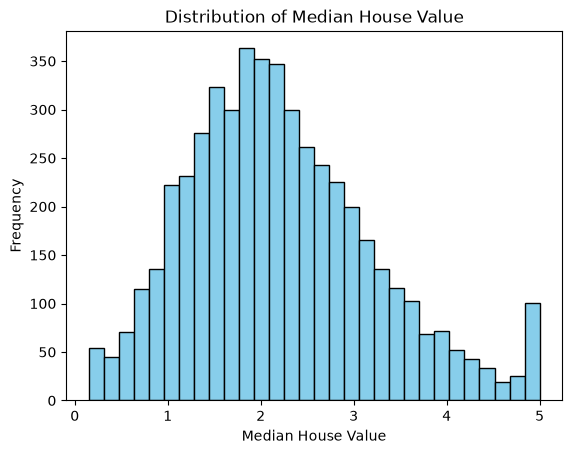

In [8]:
#plot a histogram of the target variable
plt.hist(df["MedHouseVal"], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

The target distribution is not perfectly normal and is somewhat skewed. Most observations are concentrated in the lower-to-middle range of house values, with fewer observations at higher values. Overall, the distribution is sensible for a housing-price prediction problem.

# Task-2

In [9]:
#prepare the data for moduling by splitting the dataset into feature and target variable
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

- Training data: Used to learn the model's parameters from the data.
- Validation / Cross-Validation (CV): Used to compare models and choose the best model or hyperparameters without using the test set.
- Test data: Kept completely unseen during model selection and tuning. It is used only once at the end for the final evaluation.

# Task-3

In [11]:
baseline = DummyRegressor(strategy='mean')
scores = cross_val_score(baseline, X_train, y_train, cv=5)
print('baseline CV R2:', scores.mean().round(3))

baseline CV R2: -0.002


- For regression, use DummyRegressor with strategy='mean'. For classification, DummyClassifier with strategy='most_frequent' or 'stratified'.
- Fit it on X_train only, and measure its performance using cross-validation on the training part.
- Record this number in your notebook out loud. It is your floor — every real model must beat it, or something is wrong.

# Task-4

In [12]:
# Create Linear Regression model
lr = LinearRegression()

# Train the model
lr.fit(X_train, y_train)

# Perform 5-fold cross-validation
scores = cross_val_score(
    lr,
    X_train,
    y_train,
    cv=5
)

# Print average CV R2
print("Plain LR CV R2:", scores.mean().round(3))

# Check coefficient range
print(
    "Coef range:",
    lr.coef_.min().round(2),
    "to",
    lr.coef_.max().round(2)
)

Plain LR CV R2: 0.84
Coef range: -0.14 to 0.4


The plain Linear Regression model performs better than the DummyRegressor baseline, showing that the features contain useful information for predicting median house value. The model's coefficients show how each feature contributes to the prediction. However, the features are measured on different scales, so the coefficient magnitudes are not directly comparable. In the next task, we will use StandardScaler with Ridge and Lasso regularisation to improve and compare the model.

# Task-5

In [13]:
# Ridge model with scaling
scaled_ridge = make_pipeline(
    StandardScaler(),
    Ridge()
)

In [14]:
# Lasso model with scaling
scaled_lasso = make_pipeline(
    StandardScaler(),
    Lasso()
)

In [15]:
# Ridge cross-validation
ridge_scores = cross_val_score(
    scaled_ridge,
    X_train,
    y_train,
    cv=5
)

In [16]:
# Lasso cross-validation
lasso_scores = cross_val_score(
    scaled_lasso,
    X_train,
    y_train,
    cv=5
)

In [17]:
# Print results
print("Ridge CV R2:", ridge_scores.mean().round(3))
print("Lasso CV R2:", lasso_scores.mean().round(3))

Ridge CV R2: 0.84
Lasso CV R2: -0.002


In [18]:
#Fit the models to the training data

scaled_ridge.fit(X_train, y_train)
scaled_lasso.fit(X_train, y_train)

print("Ridge coefficients:")
print(scaled_ridge.named_steps["ridge"].coef_)

print("\nLasso coefficients:")
print(scaled_lasso.named_steps["lasso"].coef_)

Ridge coefficients:
[ 0.87969133  0.16957032  0.03397028  0.00189702 -0.00217843 -0.11212972
 -0.14909487 -0.16996597]

Lasso coefficients:
[0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
lasso_coefs = scaled_lasso.named_steps["lasso"].coef_

zero_count = (lasso_coefs == 0).sum()

print("Lasso exact zero coefficients:", zero_count)

Lasso exact zero coefficients: 8


Ridge and Lasso were trained after standardising the features. Both models were evaluated using 5-fold cross-validation and compared with the baseline and plain Linear Regression. Ridge shrinks the coefficients toward zero, while Lasso can reduce some coefficients exactly to zero, providing a form of feature selection. The model with the better CV R² will be considered for further tuning in the next task.

# Task-6

In [20]:
# Create LassoCV pipeline
lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10],
        cv=5
    )
)

In [21]:
# Train the model
lasso_cv.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [22]:
# Get the best alpha
best_alpha = lasso_cv.named_steps["lassocv"].alpha_

In [23]:
# Calculate CV R2
cv_score = cross_val_score(
    lasso_cv,
    X_train,
    y_train,
    cv=5
).mean()

In [24]:
# Get Lasso model
lasso_model = lasso_cv.named_steps["lassocv"]

In [25]:
# Count zero coefficients
zero_coefficients = (lasso_model.coef_ == 0).sum()

In [26]:
# Display results
print("Best alpha:", best_alpha)
print("Best CV R2:", cv_score.round(3))
print("Number of zero coefficients:", zero_coefficients)

Best alpha: 0.001
Best CV R2: 0.84
Number of zero coefficients: 0


##### Conclusion

Lasso was tuned using 5-fold cross-validation on the training data. The best regularisation strength was alpha = 0.001, which achieved a CV R² score of 0.84. The model produced 0 zero coefficients, meaning that none of the features were completely removed by Lasso at the selected alpha. Therefore, all features contributed to the final model.


# Task-7

In [27]:
# Create the complete pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10],
        cv=5
    ))
])

In [28]:
# Train the pipeline
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [29]:
# Evaluate using 5-fold cross-validation
pipeline_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=5
)

In [30]:
# Get the best alpha
best_alpha = pipeline.named_steps["model"].alpha_

In [31]:
# Print results
print("Pipeline CV R2:", pipeline_scores.mean().round(3))
print("Best alpha:", best_alpha)

Pipeline CV R2: 0.84
Best alpha: 0.001


### Conclusion

A complete scikit-learn Pipeline was created by combining StandardScaler and LassoCV into one model. The Pipeline handles feature scaling and model training together, which helps prevent data leakage during cross-validation. The Pipeline achieved a CV R² of approximately 0.84, which is consistent with the tuned Lasso model from Task 06. The selected alpha was 0.001. Therefore, the Pipeline can now be used as the single final model for the remaining tasks.


# Task-8

In [32]:
# Extract coefficients from the trained Lasso model
coefs = pipeline.named_steps["model"].coef_

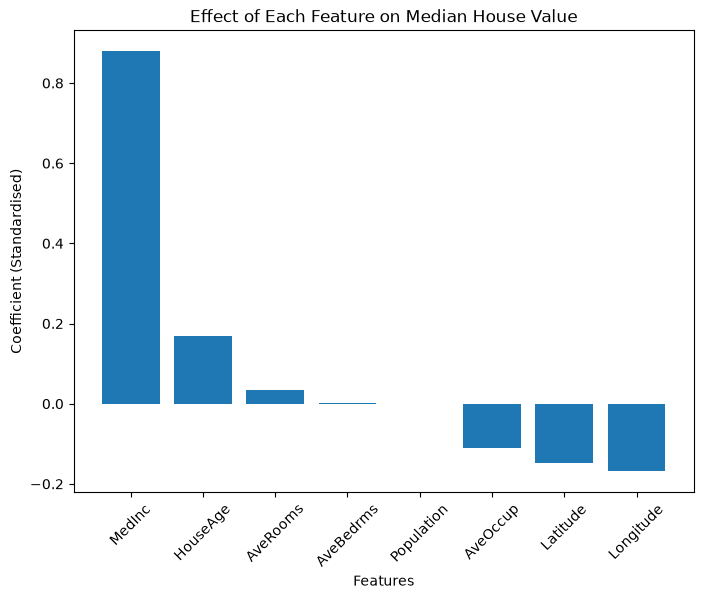

In [33]:
# Create coefficient chart
fig, ax = plt.subplots(figsize=(8, 6))

ax.bar(X.columns, coefs)

ax.set_title("Effect of Each Feature on Median House Value")
ax.set_xlabel("Features")
ax.set_ylabel("Coefficient (Standardised)")

ax.tick_params(axis="x", rotation=45)

In [34]:
# Save the chart
fig.savefig(
    "coefficients.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Display positive and negative coefficients
coef_series = pd.Series(coefs, index=X.columns)

print("Positive coefficients:")
print(coef_series[coef_series > 0].sort_values(ascending=False))

print("\nNegative coefficients:")
print(coef_series[coef_series < 0].sort_values())

Positive coefficients:
MedInc       0.878838
HouseAge     0.168567
AveRooms     0.032974
AveBedrms    0.000923
dtype: float64

Negative coefficients:
Longitude    -0.169046
Latitude     -0.148132
AveOccup     -0.111126
Population   -0.001221
dtype: float64


### Model Interpretation

The coefficient chart shows how each standardized feature contributes to the model's predicted median house value, holding the other features constant.

- MedInc has the strongest positive coefficient, approximately 0.879.
- HouseAge has a positive coefficient of approximately 0.169.
- Longitude has the most negative coefficient, approximately -0.169.
- Population has a coefficient close to zero, approximately -0.0012.

The tuned Lasso model selected alpha = 0.001 and produced zero coefficients equal to zero. Therefore, all eight input features remain in the model.

# Task-9

In [36]:
# Final evaluation on the test set
final_test_score = pipeline.score(X_test, y_test)

print("FINAL Test R2:", round(final_test_score, 3))

FINAL Test R2: 0.838


In [37]:
# Calculate CV scores for all models

baseline_cv = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5
).mean()

plain_cv = cross_val_score(
    lr,
    X_train,
    y_train,
    cv=5
).mean()

ridge_cv = cross_val_score(
    scaled_ridge,
    X_train,
    y_train,
    cv=5
).mean()

lasso_cv = cross_val_score(
    scaled_lasso,
    X_train,
    y_train,
    cv=5
).mean()

pipeline_cv = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=5
).mean()

In [38]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Final Pipeline"
    ],
    "CV R2": [
        baseline_cv,
        plain_cv,
        ridge_cv,
        lasso_cv,
        pipeline_cv
    ],
    "Test R2": [
        None,
        None,
        None,
        None,
        final_test_score
    ]
})

comparison["CV R2"] = comparison["CV R2"].round(3)
comparison["Test R2"] = comparison["Test R2"].round(3)

comparison

,Model,CV R2,Test R2
0,Baseline,-0.002,NaN
1,Linear Regression,0.840,NaN
2,Ridge,0.840,NaN
3,Lasso,-0.002,NaN
4,Final Pipeline,0.840,0.838


In [39]:
comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Comparison table saved successfully.")

Comparison table saved successfully.


### Conclusion

The final Linear Model Pipeline was evaluated on the test set after completing model selection and tuning using the training data. The final pipeline uses feature standardization and tuned Lasso regression.

The model comparison shows how the baseline, plain Linear Regression, Ridge, Lasso, and the final pipeline perform using cross-validation. The test set was kept separate during model selection and was used only for the final evaluation.

The final test R² gives an unbiased estimate of how well the selected pipeline performs on unseen data.